In [31]:
import numpy as np
import pandas as pd

# Дані опадів для Києва (Варіант 1)
precip = [47, 44, 38, 43, 60, 78, 88, 70, 48, 41, 47, 50]

# 1. Варіаційний ряд (відсортовані значення)
var_series = np.sort(precip)
print("Варіаційний ряд:", var_series)

# 2. Розбиття на 4 інтервали та побудова частотної таблиці
# Визначаємо мітки інтервалів та біни від мінімального до максимального значення
bins = [35, 50, 65, 80, 90]
labels = ["35-50", "50-65", "65-80", "80-90"]

s = pd.Series(precip)
cat = pd.cut(s, bins=bins, labels=labels, right=True)

freq = cat.value_counts().sort_index()
rel = cat.value_counts(normalize=True).sort_index() * 100
cum = freq.cumsum()

freq_table = pd.DataFrame({
    "абсолютна частота": freq,
    "відносна частота (%)": rel.round(1),
    "накопичена частота": cum
})
print("\nЧастотна таблиця:")
display(freq_table)

Варіаційний ряд: [38 41 43 44 47 47 48 50 60 70 78 88]

Частотна таблиця:


,абсолютна частота,відносна частота (%),накопичена частота
35-50,8,66.7,8
50-65,1,8.3,9
65-80,2,16.7,11
80-90,1,8.3,12


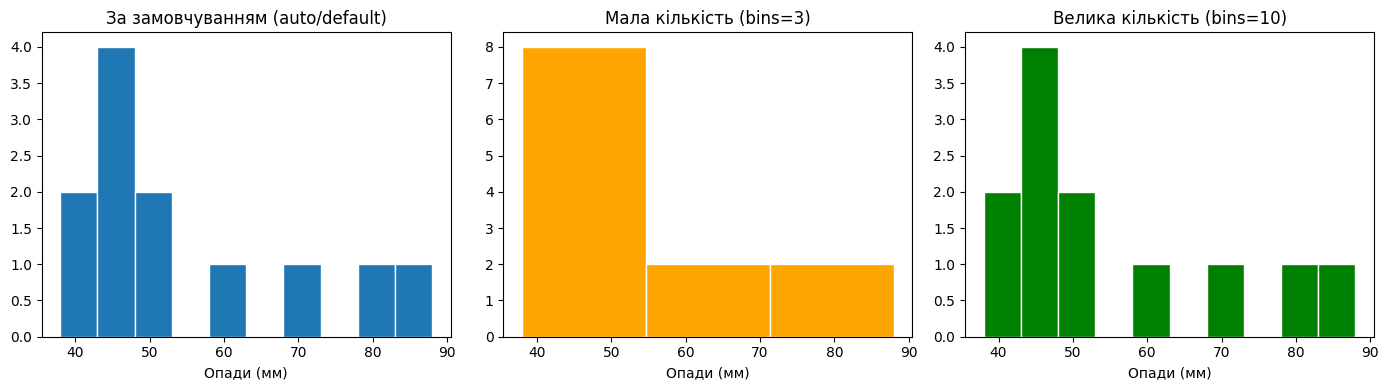

Правило Стерджеса (1 + log2(12)): 4.58 -> рекомендовано ~4-5 інтервалів
Правило квадратного кореня (sqrt(12)): 3.46 -> рекомендовано ~3-4 інтервали


In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

# 1. За замовчуванням
plt.subplot(1, 3, 1)
plt.hist(precip, edgecolor="white")
plt.title("За замовчуванням (auto/default)")
plt.xlabel("Опади (мм)")

# 2. Мала кількість інтервалів (bins=3)
plt.subplot(1, 3, 2)
plt.hist(precip, bins=3, edgecolor="white", color="orange")
plt.title("Мала кількість (bins=3)")
plt.xlabel("Опади (мм)")

# 3. Велика кількість інтервалів (bins=10)
plt.subplot(1, 3, 3)
plt.hist(precip, bins=10, edgecolor="white", color="green")
plt.title("Велика кількість (bins=10)")
plt.xlabel("Опади (мм)")

plt.tight_layout()
plt.show()

# Розрахунок кількості інтервалів за правилами для n = 12:
n = len(precip)
sturges = 1 + np.log2(n)
sqrt_rule = np.sqrt(n)
print(f"Правило Стерджеса (1 + log2(12)): {sturges:.2f} -> рекомендовано ~4-5 інтервалів")
print(f"Правило квадратного кореня (sqrt(12)): {sqrt_rule:.2f} -> рекомендовано ~3-4 інтервали")

In [33]:
s_precip = pd.Series(precip)

mean_val = s_precip.mean()
median_val = s_precip.median()
mode_val = s_precip.mode()[0]
q1 = s_precip.quantile(0.25)
q3 = s_precip.quantile(0.75)

print(f"Середнє арифметичне: {mean_val:.2f}")
print(f"Медіана: {median_val}")
print(f"Мода: {mode_val}")
print(f"Q1 (25-й процентиль): {q1}")
print(f"Q3 (75-й процентиль): {q3}")

Середнє арифметичне: 54.50
Медіана: 47.5
Мода: 47
Q1 (25-й процентиль): 43.75
Q3 (75-й процентиль): 62.5


### Відповіді на контрольні запитання:

1. **Чому середнє арифметичне некоректне для номінальної змінної "місто", навіть якщо закодувати міста числами:**
   - Номінальна шкала відображає лише якісні категорії без кількісного порядку. Штучне присвоєння числах назвам міст (наприклад, Київ = 1, Львів = 2) є довільним і не робить ці числа справжніми кількісними величинами. Обчислення середнього арифметичного з таких кодів дасть беззмістовне математичне число, яке не відповідає жодній реальній характеристиці об'єктів.

2. **Чому "номер місяця" — приклад неоднозначної класифікації за шкалою вимірювання:**
   - З одного боку, місяці мають фіксовану послідовність (порядкова шкала), з іншого — інтервали між ними за тривалістю майже рівні, як в інтервальній шкалі. Проте у шкали відсутній абсолютний нуль (немає «нульового місяця»), що не дозволяє повністю віднести її до інтервальної чи шкали відношень у класичному строглому розумінні, створюючи проміжний характер.

3. **Чому для "кількості опадів" потрібна гістограма з інтервалами, а не стовпчикова діаграма:**
   - Оскільки кількісні неперервні дані опадів складаються майже з повністю унікальних значень (12 різних чисел на 12 місяців), побудова стовпчикової діаграми за окремими точними значеннями призведе до того, що кожний стовпчик матиме висоту 1. Гістограма з розбиттям на інтервали групує близькі значення в діапазони, дозволяючи наочно побачити загальну частоту та форму розподілу.

4. **Змістовне значення накопиченої частоти на межі третього інтервалу:**
   - Накопичена частота на межі третього інтервалу показує кумулятивну кількість (або частку) місяців у році, рівень опадів у яких не перевищує верхню межу цього інтервалу, що дає змогу оцінити кумулятивний розподіл кліматичних умов за періоди.